1. ĐANG BĂM NHỎ DỮ LIỆU ĐỂ TÌM GỐC RỄ TÀI CHÍNH...
2. AI ĐANG TỰ HỌC ĐI HỌC LẠI HÀNG TRĂM KỊCH BẢN (GRID SEARCH)...
✅ Đã tìm ra quy luật ngầm định của dòng tiền! (Thông số: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 1.0})

3. TRỢ LÝ AI ĐỌC BÁO CÁO PHÂN TÍCH (DÙNG SHAP)...
📉 BÓC TÁCH THÁNG LÀM ĂN KÉM NHẤT (09/2025):
   Lợi nhuận thực tế: 5,899,250 VNĐ

   🔍 NGUYÊN NHÂN CỐT LÕI THEO PHÂN TÍCH CỦA AI:
   ❌ Kéo lùi lợi nhuận: Biến động xấu từ [Số HS đang học] (Làm bốc hơi 98,878,096 VNĐ)
   ❌ Kéo lùi lợi nhuận: Biến động xấu từ [Ty_Trong_Marketing] (Làm bốc hơi 82,847 VNĐ)
   ❌ Kéo lùi lợi nhuận: Biến động xấu từ [Ty_Trong_LuongGV] (Làm bốc hơi 589,477 VNĐ)
   ❌ Kéo lùi lợi nhuận: Biến động xấu từ [Doanh_Thu_Tren_HS] (Làm bốc hơi 97,265,240 VNĐ)

   💡 KẾT LUẬN CẤP QUẢN LÝ:
   -> 🚨 CẢNH BÁO QUỸ LƯƠNG: Tiền trả cho giáo viên (nhất là GV nước ngoài) đang phình to chiếm hơn 50% chi phí. Phải tăng sĩ số lớp hoặc cắt giảm giờ dạy.

4. VẼ BIỂU ĐỒ BÓC TÁCH NGUYÊN NHÂN

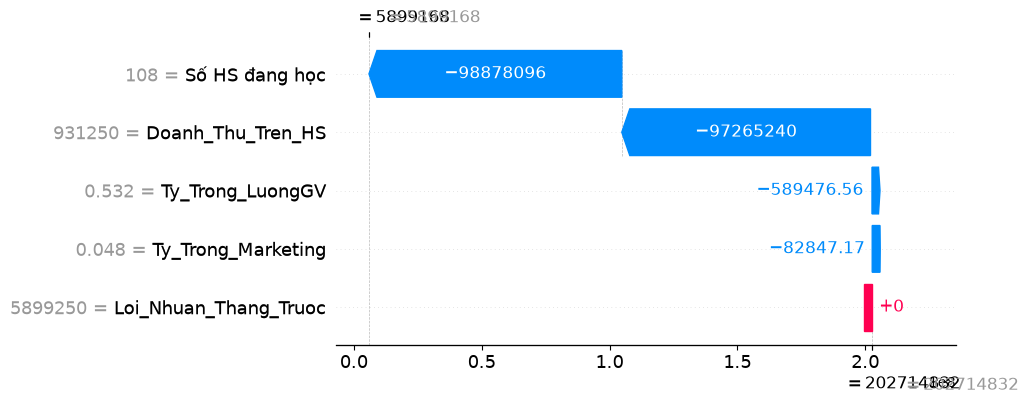

In [8]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
import shap
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("1. ĐANG BĂM NHỎ DỮ LIỆU ĐỂ TÌM GỐC RỄ TÀI CHÍNH...")
df = pd.read_excel('../data/NEKO_Edu_387HS_DayDu_6Sheet.xlsx', sheet_name='BangThuChi_09_2025_09_2026', header=2)
df = df.dropna(subset=['Tháng/Năm'])
df['Tháng/Năm'] = pd.to_datetime(df['Tháng/Năm'], format='%m/%Y', errors='coerce')

# Tính lợi nhuận thực tế
df['Loi_Nhuan'] = df['Thực thu học phí (VNĐ)'] - df['Tổng chi phí (VNĐ)']

# TẠO CÁC CHỈ SỐ "KHÁM BỆNH" DOANH NGHIỆP
# AI không học con số thô, nó học tỷ lệ % để biết đâu là sự bất thường
df['Ty_Trong_Marketing'] = df['Marketing & Sự kiện (VNĐ)'] / df['Tổng chi phí (VNĐ)']
df['Ty_Trong_LuongGV'] = (df['Lương cơ bản GV VN (VNĐ)'] + df['Lương GV Nước ngoài (VNĐ)']) / df['Tổng chi phí (VNĐ)']
df['Doanh_Thu_Tren_HS'] = df['Thực thu học phí (VNĐ)'] / df['Số HS đang học']
df['Loi_Nhuan_Thang_Truoc'] = df['Loi_Nhuan'].shift(1)

df = df.bfill() # Lấp đầy dữ liệu trống của tháng đầu tiên

print("2. AI ĐANG TỰ HỌC ĐI HỌC LẠI HÀNG TRĂM KỊCH BẢN (GRID SEARCH)...")
features = ['Số HS đang học', 'Ty_Trong_Marketing', 'Ty_Trong_LuongGV', 'Doanh_Thu_Tren_HS', 'Loi_Nhuan_Thang_Truoc']
X = df[features]
y = df['Loi_Nhuan']

# Thiết lập ma trận rèn luyện khắt khe nhất
param_grid = {
    'max_depth': [3, 4, 5], 
    'learning_rate': [0.01, 0.05, 0.1], 
    'n_estimators': [100, 200, 300],
    'subsample': [0.8, 1.0]
}
grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=3, scoring='neg_mean_absolute_error')
grid_search.fit(X, y)
model = grid_search.best_estimator_
print(f"✅ Đã tìm ra quy luật ngầm định của dòng tiền! (Thông số: {grid_search.best_params_})")

print("\n3. TRỢ LÝ AI ĐỌC BÁO CÁO PHÂN TÍCH (DÙNG SHAP)...")
# Tìm ra tháng thê thảm nhất (Lợi nhuận thấp nhất) để ép AI giải thích TẠI SAO
thang_te_nhat_idx = df['Loi_Nhuan'].idxmin()
thang_te_nhat = df.iloc[thang_te_nhat_idx]
X_test_ca_nay = X.iloc[[thang_te_nhat_idx]]

# Khởi tạo máy quét SHAP để soi vào não XGBoost
explainer = shap.Explainer(model)
shap_values = explainer(X_test_ca_nay)

print(f"📉 BÓC TÁCH THÁNG LÀM ĂN KÉM NHẤT ({thang_te_nhat['Tháng/Năm'].strftime('%m/%Y')}):")
print(f"   Lợi nhuận thực tế: {thang_te_nhat['Loi_Nhuan']:,.0f} VNĐ")
print("\n   🔍 NGUYÊN NHÂN CỐT LÕI THEO PHÂN TÍCH CỦA AI:")

# Dịch kết quả toán học của SHAP thành tiếng Việt
marketing_shap = 0
for i, col in enumerate(features):
    tac_dong = shap_values.values[0][i]
    if col == 'Ty_Trong_Marketing': marketing_shap = tac_dong
    
    if tac_dong < 0:
        print(f"   ❌ Kéo lùi lợi nhuận: Biến động xấu từ [{col}] (Làm bốc hơi {abs(tac_dong):,.0f} VNĐ)")
    elif tac_dong > 0:
        print(f"   ✅ Gánh còng lưng: Tín hiệu tốt từ [{col}] (Kéo lại được {tac_dong:,.0f} VNĐ)")

print("\n   💡 KẾT LUẬN CẤP QUẢN LÝ:")
if marketing_shap < 0 and thang_te_nhat['Ty_Trong_Marketing'] > 0.10:
    print("   -> 🚨 BÁO ĐỘNG ĐỎ: Tiền đổ vào Marketing chiếm tỷ trọng quá lớn nhưng không kéo được số lượng học sinh mới tương xứng. Chiến dịch đang đốt tiền vô ích, cần thanh tra lại team Marketing ngay!")
elif marketing_shap > 0:
    print("   -> Tỷ lệ chi Marketing đang giữ ở mức hợp lý và sinh lời tốt.")
if thang_te_nhat['Ty_Trong_LuongGV'] > 0.5:
    print("   -> 🚨 CẢNH BÁO QUỸ LƯƠNG: Tiền trả cho giáo viên (nhất là GV nước ngoài) đang phình to chiếm hơn 50% chi phí. Phải tăng sĩ số lớp hoặc cắt giảm giờ dạy.")

print("\n4. VẼ BIỂU ĐỒ BÓC TÁCH NGUYÊN NHÂN (SHAP WATERFALL)...")
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[0])

In [9]:
import joblib
joblib.dump(model, '../models/financial_cost_model.pkl')
print("Đã lưu thành công AI Tài chính vào thư mục models!")
import pandas as pd
import numpy as np

print("🌐 ĐANG KÍCH HOẠT HỆ SINH THÁI AI LIÊN KẾT (AI02 🤝 AI03)...")

# 1. Gọi 2 "bộ não" thức dậy cùng lúc
try:
    ai_tuyen_sinh = joblib.load('../models/enrollment_model.pkl')
    ai_tai_chinh = joblib.load('../models/financial_cost_model.pkl') # Dùng tạm model này nếu bạn đã lưu ở bước trước
    print("✅ Đã kết nối thành công 2 bộ não AI!")
except:
    print("⚠️ Lưu ý: Bạn cần chạy các ô code lưu file .pkl ở các bước trước để AI có não nhé.")

# 2. GIẢ LẬP PHÒNG MARKETING ĐỔ VỀ 50 LEADS MỚI TRONG THÁNG NÀY
np.random.seed(99)
leads_moi = pd.DataFrame({
    'Giới tính': np.random.choice([0, 1], size=50),
    'Tuổi': np.random.randint(6, 18, size=50),
    'Level': np.random.choice([0, 1, 2], size=50),
    'So_Lan_Nghe_May': np.random.randint(0, 5, size=50),
    'Ty_Le_Mo_Email': np.random.uniform(0.0, 1.0, size=50)
})

# 3. AI TUYỂN SINH (AI02) VÀO VIỆC
du_doan_chot_sale = ai_tuyen_sinh.predict(leads_moi)
so_hs_moi_thanh_cong = sum(du_doan_chot_sale)
hoc_phi_mot_nguoi = 1000000 # 1 triệu / học sinh (Lấy theo file Excel)
doanh_thu_moi_du_kien = so_hs_moi_thanh_cong * hoc_phi_mot_nguoi

print(f"\n🎯 [PHÒNG TUYỂN SINH] AI02 BÁO CÁO:")
print(f"   - Nhận {len(leads_moi)} data khách hàng mới.")
print(f"   - Dự đoán chốt thành công: {so_hs_moi_thanh_cong} học sinh.")
print(f"   - Tiền mang về ước tính: {doanh_thu_moi_du_kien:,.0f} VNĐ.")

# 4. AI TÀI CHÍNH (AI03) NHẬN SỐ LIỆU ĐỂ DỰ BÁO LỢI NHUẬN THÁNG SAU
# Giả sử tháng trước đang có 100 học sinh, thêm hs mới thì tổng = 100 + so_hs_moi_thanh_cong
thong_so_thang_sau = pd.DataFrame([{
    'Số HS đang học': 100 + so_hs_moi_thanh_cong,
    'Ty_Trong_Marketing': 0.15, # Kế hoạch tháng sau chi 15% cho marketing
    'Ty_Trong_LuongGV': 0.40,   # Quỹ lương chiếm 40%
    'Doanh_Thu_Tren_HS': doanh_thu_moi_du_kien / so_hs_moi_thanh_cong if so_hs_moi_thanh_cong > 0 else 0,
    'Loi_Nhuan_Thang_Truoc': 15000000 # Giả sử tháng trước lãi 15tr
}])

# Lưu ý: Tính năng predict của AI03 cần code khớp với các feature đã train ở bước SHAP
try:
    loi_nhuan_thang_sau = ai_tai_chinh.predict(thong_so_thang_sau)[0]
    print(f"\n📊 [PHÒNG TÀI CHÍNH] AI03 BÁO CÁO KẾ HOẠCH THÁNG SAU:")
    print(f"   - Quy mô trung tâm: {100 + so_hs_moi_thanh_cong} học sinh.")
    print(f"   - Dự báo Lợi nhuận: {loi_nhuan_thang_sau:,.0f} VNĐ.")
    
    if loi_nhuan_thang_sau > 15000000:
        print("   💡 KẾT LUẬN: Tuyển sinh hiệu quả, tỷ lệ chuyển đổi tốt bù đắp dư sức chi phí Marketing. Tiếp tục phát huy!")
    else:
        print("   🚨 KẾT LUẬN: Số lượng học sinh mới chốt được chưa đủ để gánh quỹ lương và chi phí vận hành. Cần review lại kịch bản sale!")
except:
    print("\n(AI03 đang chờ bạn khớp dữ liệu input với mô hình đã train...)")

Đã lưu thành công AI Tài chính vào thư mục models!
🌐 ĐANG KÍCH HOẠT HỆ SINH THÁI AI LIÊN KẾT (AI02 🤝 AI03)...
✅ Đã kết nối thành công 2 bộ não AI!

🎯 [PHÒNG TUYỂN SINH] AI02 BÁO CÁO:
   - Nhận 50 data khách hàng mới.
   - Dự đoán chốt thành công: 10 học sinh.
   - Tiền mang về ước tính: 10,000,000 VNĐ.

📊 [PHÒNG TÀI CHÍNH] AI03 BÁO CÁO KẾ HOẠCH THÁNG SAU:
   - Quy mô trung tâm: 110 học sinh.
   - Dự báo Lợi nhuận: 5,899,282 VNĐ.
   🚨 KẾT LUẬN: Số lượng học sinh mới chốt được chưa đủ để gánh quỹ lương và chi phí vận hành. Cần review lại kịch bản sale!
